# 04 – Xây dựng nhãn, Feature Engineering và Lựa chọn đặc trưng (Feature Selection)

**Mục tiêu:** từ `cleaned_dataset.csv` (7.999 sản phẩm) tạo bộ dữ liệu sẵn sàng cho mô hình:
1. Xây nhãn 3 mức **Healthy / Moderate / Less Healthy** *độc lập với Nutri-Score* (dựa trên ngưỡng "đèn giao thông" của FSA – Anh).
2. Tạo các biến phái sinh.
3. Khai báo bộ đặc trưng và **kiểm soát rò rỉ dữ liệu**.
4. **Chia train/test 80/20** (phân tầng theo nhãn và danh mục).
5. Kiểm tra và chọn đặc trưng **chỉ trên tập train**.
6. Lưu `train.csv`, `test.csv` (và `feature_dataset.csv` đầy đủ) cho notebook 05 (huấn luyện mô hình).

**Về rò rỉ dữ liệu (quan trọng):** nhãn của nhóm được tính từ 4 chất (béo, béo bão hòa, đường, muối). Nếu đưa chính 4 chất đó vào làm đặc trưng thì mô hình chỉ học lại công thức tính nhãn, độ chính xác cao nhưng vô nghĩa. Vì vậy bộ đặc trưng **không chứa 4 chất tạo nhãn** (cũng không chứa biến suy ra từ chúng). `nutriscore_grade`, `nutriscore_score`, `nova_group` cũng không bao giờ được dùng làm đặc trưn

## 1. Đọc dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEED = 42
df = pd.read_csv("cleaned_dataset.csv", dtype={"code": str})
print(df.shape)
print(df["main_category"].value_counts())

(7999, 32)
main_category
dairies      2214
snacks       2202
meals        2166
beverages    1417
Name: count, dtype: int64


## 2. Xây nhãn chất lượng dinh dưỡng (độc lập với Nutri-Score)

Dùng ngưỡng nhãn đèn giao thông của FSA (Anh) cho 4 chất: **béo, béo bão hòa, đường, muối**. Thực phẩm tính trên 100 g, **đồ uống có ngưỡng riêng** (tính trên 100 ml, nghiêm hơn).

#### 1. Ngưỡng đánh giá FSA (`thực phẩm / đồ uống`)
| Chất dinh dưỡng | Ngưỡng Thấp (≤) / Cao (>) cho Thực phẩm | Ngưỡng Thấp (≤) / Cao (>) cho Đồ uống |
| :--- | :--- | :--- |
| **Béo (`fat_100g`)** | 3.0 g / 17.5 g | 1.5 g / 8.75 g |
| **Béo bão hòa (`saturated-fat_100g`)** | 1.5 g / 5.0 g | 0.75 g / 2.5 g |
| **Đường (`sugars_100g`)** | 5.0 g / 22.5 g | 2.5 g / 11.25 g |
| **Muối (`salt_100g`)** | 0.3 g / 1.5 g | 0.3 g / 0.75 g |

#### 2. Quy tắc tính điểm & Đếm số ô đỏ (`n_red`)
* **Điểm từng chất:** Thấp ($\le$ low) = 0đ | Trung bình = 1đ | Cao (> high) = 2đ.
* **Tổng điểm FSA (`fsa_points`):** Tổng điểm của 4 chất (0 – 8 điểm).
* **Số ô đỏ (`n_red`):** Số lượng chất đạt mức "Cao" (điểm = 2).

#### 3. Quy tắc chọn nhãn phân loại (`health_label`)
* **Less Healthy:** Khi có $\ge 2$ chất đạt mức cao (`n_red >= 2`) HOẶC tổng điểm FSA từ 5 trở lên (`p >= 5`).
* **Healthy:** Khi không có chất nào đạt mức cao (`r == 0`) VÀ tổng điểm FSA từ 2 trở xuống (`p <= 2`).
* **Moderate:** Các trường hợp còn lại (Điểm và số ô đỏ ở mức trung gian).



In [2]:
# (thấp, cao) cho thực phẩm và đồ uống
FSA = {
    "fat_100g":           {"food": (3.0, 17.5), "drink": (1.5, 8.75)},
    "saturated-fat_100g": {"food": (1.5, 5.0),  "drink": (0.75, 2.5)},
    "sugars_100g":        {"food": (5.0, 22.5), "drink": (2.5, 11.25)},
    "salt_100g":          {"food": (0.3, 1.5),  "drink": (0.3, 0.75)},
}
LABEL_NUTRIENTS = list(FSA)
is_drink = df["main_category"] == "beverages"

fsa_points = pd.DataFrame(index=df.index)
for col, th in FSA.items():
    low = np.where(is_drink, th["drink"][0], th["food"][0])
    high = np.where(is_drink, th["drink"][1], th["food"][1])
    fsa_points[col] = np.where(df[col] > high, 2, np.where(df[col] > low, 1, 0))

df["fsa_points"] = fsa_points.sum(axis=1)
df["n_red"] = (fsa_points == 2).sum(axis=1)

# Quy tắc chọn nhãn (xem bảng quy tắc ở trên)
def to_label(row):
    p = row["fsa_points"]
    r = row["n_red"]
    if r >= 2 or p >= 5:
        return "Less Healthy"
    if r == 0 and p <= 2:
        return "Healthy"
    return "Moderate"

df["health_label"] = df.apply(to_label, axis=1)
LABELS = ["Healthy", "Moderate", "Less Healthy"]

print("Phân bố nhãn:")
print(df["health_label"].value_counts().reindex(LABELS))
print("\nTỷ lệ (%):")
print((df["health_label"].value_counts(normalize=True).reindex(LABELS) * 100).round(1))

Phân bố nhãn:
health_label
Healthy         3435
Moderate        2110
Less Healthy    2454
Name: count, dtype: int64

Tỷ lệ (%):
health_label
Healthy         42.9
Moderate        26.4
Less Healthy    30.7
Name: proportion, dtype: float64


health_label   Healthy  Moderate  Less Healthy
main_category                                 
beverages         80.5      14.4           5.2
dairies           41.1      19.4          39.5
meals             56.1      40.1           3.8
snacks             7.7      27.7          64.7


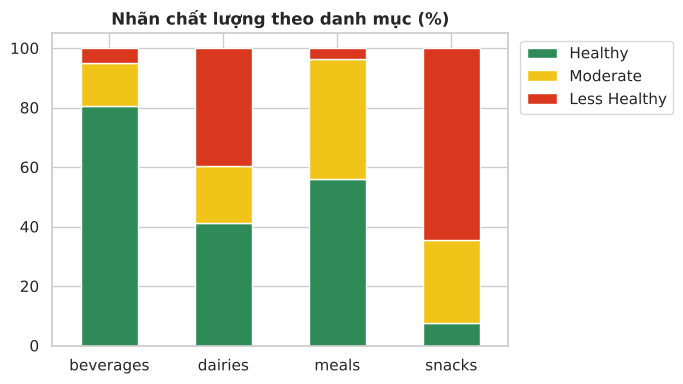

In [3]:
# Nhãn theo danh mục
ct = (pd.crosstab(df["main_category"], df["health_label"], normalize="index")[LABELS] * 100).round(1)
print(ct)
ct.plot(kind="bar", stacked=True, color=["#2e8b57", "#f0c419", "#d9381e"], figsize=(7, 4), edgecolor="white")
plt.title("Nhãn chất lượng theo danh mục (%)", fontweight="bold")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("fe_label_by_category.png", dpi=120)
plt.show()

### Nhãn mới có độc lập với Nutri-Score không?
Nutri-Score dùng thêm năng lượng, đạm, chất xơ, trái cây/rau; nhãn FSA ở đây không dùng. Ta đối chiếu bằng cách gộp Nutri-Score: A,B → Healthy; C → Moderate; D,E → Less Healthy. Hai nhãn nên **tương quan nhưng không trùng**.

In [4]:
known = df.dropna(subset=["nutriscore_grade"]).copy()
known["nutri_3"] = known["nutriscore_grade"].map({"A": "Healthy", "B": "Healthy", "C": "Moderate", "D": "Less Healthy", "E": "Less Healthy"})
print("Tỷ lệ trùng khớp nhãn FSA và Nutri-Score gộp:", round((known["nutri_3"] == known["health_label"]).mean() * 100, 1), "%")
print("\nHàng: Nutri-Score gốc, cột: nhãn FSA (%)")
print((pd.crosstab(known["nutriscore_grade"], known["health_label"], normalize="index")[LABELS] * 100).round(1))

Tỷ lệ trùng khớp nhãn FSA và Nutri-Score gộp: 65.0 %

Hàng: Nutri-Score gốc, cột: nhãn FSA (%)
health_label      Healthy  Moderate  Less Healthy
nutriscore_grade                                 
A                    92.3       6.1           1.6
B                    87.2      12.2           0.6
C                    47.6      45.0           7.4
D                    13.4      34.0          52.7
E                    10.6      12.4          77.0


**Nhận xét:** hai nhãn cùng chiều (A,B phần lớn là Healthy; E phần lớn là Less Healthy) nhưng không trùng hoàn toàn (khoảng 65% khớp, xem kết quả phía trên). Nhãn FSA chỉ nhìn 4 chất cần hạn chế nên không "thưởng" cho chất xơ/đạm như Nutri-Score; do đó đây là nhãn độc lập, có thể dùng để kiểm chứng chéo với Nutri-Score ở notebook 06.

## 3. Tạo biến phát sinh
- `protein_energy_share`: % năng lượng đến từ đạm
- `has_fiber`: có khai báo chất xơ hay không
- Danh mục `main_category` được mã hóa one-hot ở bước mô hình

In [5]:
en = df["energy-kcal_100g"].replace(0, np.nan)   # năng lượng 0 (nước lọc...) -> chia ra NaN, gán 0 bên dưới

df["protein_energy_share"] = (df["proteins_100g"] * 4 / en * 100).clip(0, 100).fillna(0)
df["has_fiber"] = df["fiber_100g"].notna().astype(int)

stats = df[["protein_energy_share", "has_fiber"]].describe().round(2).T
stats["count"] = stats["count"].astype(int)
print(stats)

                      count   mean    std  min   25%    50%    75%    max
protein_energy_share   7999  15.40  15.28  0.0  5.25  10.59  21.11  100.0
has_fiber              7999   0.69   0.46  0.0  0.00   1.00   1.00    1.0


## 4. Khai báo đặc trưng ứng viên và kiểm soát rò rỉ

In [6]:
# Bộ đặc trưng: KHÔNG chứa 4 chất tạo nhãn (béo, béo bão hòa, đường, muối) hay biến suy ra từ chúng
FEATURES = ["energy-kcal_100g", "proteins_100g", "fiber_100g", "additives_n", "protein_energy_share", "has_fiber"]
# Tuyệt đối không dùng làm feature:
FORBIDDEN = ["nutriscore_grade", "nutriscore_score", "nova_group", "fsa_points", "n_red", "health_label"]

assert not set(FORBIDDEN) & set(FEATURES)
assert not set(LABEL_NUTRIENTS) & set(FEATURES)
print("Đặc trưng :", FEATURES)
print("Loại (tạo nhãn):", LABEL_NUTRIENTS)
print("Cấm       :", FORBIDDEN)

Đặc trưng : ['energy-kcal_100g', 'proteins_100g', 'fiber_100g', 'additives_n', 'protein_energy_share', 'has_fiber']
Loại (tạo nhãn): ['fat_100g', 'saturated-fat_100g', 'sugars_100g', 'salt_100g']
Cấm       : ['nutriscore_grade', 'nutriscore_score', 'nova_group', 'fsa_points', 'n_red', 'health_label']


## 5. Chia train / test (80/20)
Chia **trước** khi kiểm tra và chọn đặc trưng, để tập test không tham gia vào bất kỳ quyết định nào. Tỷ lệ 80/20, phân tầng theo nhãn + danh mục để hai tập giữ cùng cơ cấu. Việc điền thiếu và chuẩn hóa nằm trong pipeline ở notebook 05 và chỉ học trên train.

In [7]:
strat = df["health_label"] + "|" + df["main_category"]
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=SEED, stratify=strat)
df["split"] = "train"
df.loc[test_idx, "split"] = "test"
train = df[df["split"] == "train"].copy()

print(df["split"].value_counts())
print("\nNhãn (%) theo tập:")
print((pd.crosstab(df["split"], df["health_label"], normalize="index")[LABELS] * 100).round(1))
print("\nDanh mục (%) theo tập:")
print((pd.crosstab(df["split"], df["main_category"], normalize="index") * 100).round(1))
print("\nTrùng mã vạch giữa train và test:", len(set(train["code"]) & set(df.loc[df.split == "test", "code"])))

split
train    6399
test     1600
Name: count, dtype: int64

Nhãn (%) theo tập:
health_label  Healthy  Moderate  Less Healthy
split                                        
test             42.9      26.4          30.6
train            42.9      26.4          30.7

Danh mục (%) theo tập:
main_category  beverages  dairies  meals  snacks
split                                           
test                17.7     27.7   27.1    27.6
train               17.7     27.7   27.1    27.5

Trùng mã vạch giữa train và test: 0


## 6. Kiểm tra các đặc trưng đã chọn (chỉ trên tập train)

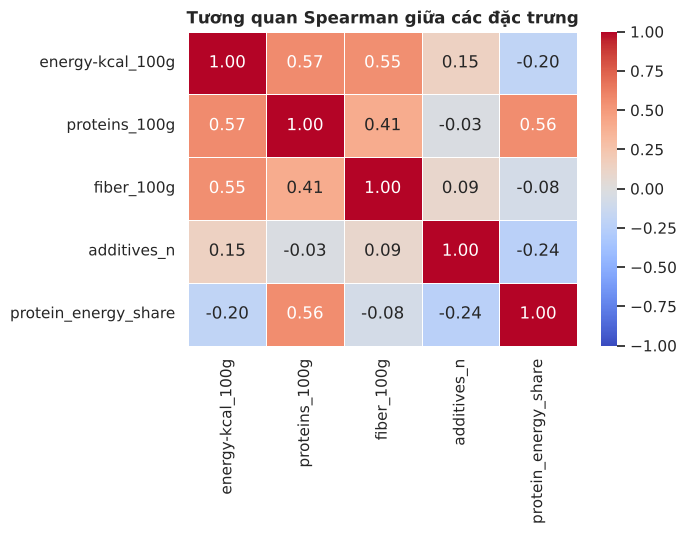

Các cặp |r| >= 0.85:
Series([], dtype: float64)


In [8]:
# 5.1 Tương quan Spearman giữa các đặc trưng (phát hiện đa cộng tuyến)
num = [c for c in FEATURES if c != "has_fiber"]
corr = train[num].corr(method="spearman")
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Tương quan Spearman giữa các đặc trưng", fontweight="bold")
plt.tight_layout()
plt.savefig("fe_feature_corr.png", dpi=120)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Các cặp |r| >= 0.85:")
print(pairs[pairs.abs() >= 0.85].round(2).sort_values(ascending=False))

                      mutual_info  duoc_chon
saturated-fat_100g          0.613      False
fat_100g                    0.603      False
energy-kcal_100g            0.526       True
sugars_100g                 0.252      False
protein_energy_share        0.233       True
proteins_100g               0.192       True
salt_100g                   0.147      False
fiber_100g                  0.059       True
additives_n                 0.008       True
has_fiber                   0.000       True


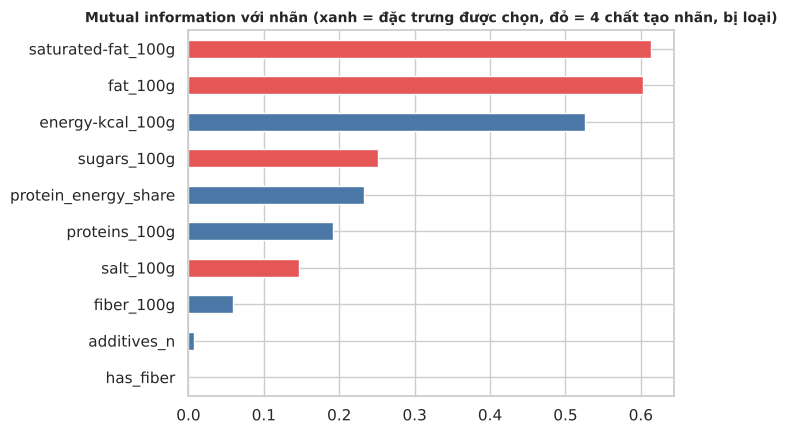

In [9]:
# 5.2 Mutual information với nhãn (đo mức thông tin mỗi biến cung cấp, kể cả quan hệ phi tuyến)
# Tính cho đặc trưng được chọn và cho 4 chất tạo nhãn (chỉ để cho thấy vì sao phải loại chúng)
cols = FEATURES + LABEL_NUTRIENTS
X = train[cols].copy()
X = X.fillna(X.median())
mi = pd.Series(mutual_info_classif(X, train["health_label"], random_state=SEED), index=cols).sort_values(ascending=False)
mi_tab = pd.DataFrame({"mutual_info": mi.round(3), "duoc_chon": [f in FEATURES for f in mi.index]})
print(mi_tab)
mi.sort_values().plot(kind="barh", figsize=(7, 4.5), color=["#4c78a8" if f in FEATURES else "#e45756" for f in mi.sort_values().index])
plt.title("Mutual information với nhãn (xanh = đặc trưng được chọn, đỏ = 4 chất tạo nhãn, bị loại)", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig("fe_mutual_info.png", dpi=120)
plt.show()

In [10]:
# 5.3 Kiểm tra giá trị thiếu của các đặc trưng
print((train[FEATURES].isna().mean() * 100).round(1))

energy-kcal_100g         0.0
proteins_100g            0.0
fiber_100g              30.6
additives_n              5.2
protein_energy_share     0.0
has_fiber                0.0
dtype: float64


**Nhận xét và quyết định chọn đặc trưng:**
- Béo bão hòa (0,61) và béo (0,60) có mutual information cao nhất, cao hơn cả năng lượng (0,53); đường (0,25) và muối (0,15) thấp hơn năng lượng. Dù vậy nhãn được tính trực tiếp từ cả 4 chất, nên đều phải **loại** khỏi bộ đặc trưng để mô hình không học lại công thức tạo nhãn.
- Bộ đặc trưng gồm: năng lượng, đạm, chất xơ, số phụ gia, % năng lượng từ đạm, cờ `has_fiber` và danh mục sản phẩm (one-hot trong pipeline ở notebook 05). Các biến số không có cặp nào tương quan quá cao (không có cặp |r| ≥ 0,85) nên giữ nguyên.
- Năng lượng là biến mang nhiều thông tin nhất vì phản ánh béo và đường gián tiếp, nhưng nó không phải là công thức tạo nhãn nên không gây rò rỉ trực tiếp.
- `additives_n` và `has_fiber` có mutual information gần 0, tức là đứng một mình gần như không phân biệt được nhãn. Vẫn giữ lại vì chi phí thấp, phụ gia liên quan tới NOVA (đã thấy ở EDA) và có thể bổ sung thông tin khi kết hợp với biến khác; notebook 06 sẽ kiểm tra lại bằng permutation importance.
- Chất xơ thiếu ~31% và phụ gia ~5%: **không điền ở đây**; sẽ điền trung vị bên trong pipeline và chỉ học trên tập train để tránh rò rỉ từ test.

## 7. Lưu bộ dữ liệu đặc trưng
Lưu riêng tập train và tập test để notebook 05 đọc thẳng, không phải chia lại. `feature_dataset.csv` là bản đầy đủ (có cột `split`), dùng cho K-Means và phần tổng hợp ở notebook 07.

In [11]:
# Giữ lại 4 chất tạo nhãn trong file dữ liệu (dùng cho K-Means ở notebook 05), nhưng KHÔNG dùng làm đặc trưng
keep = (["code", "product_name", "brand_main", "main_category", "country_single", "health_label", "fsa_points", "split"]
        + FEATURES + LABEL_NUTRIENTS + ["nutriscore_grade", "nova_group"])
keep = list(dict.fromkeys(keep))
df[keep].to_csv("feature_dataset.csv", index=False, encoding="utf-8-sig")
out = df[keep]
out[out["split"] == "train"].to_csv("train.csv", index=False, encoding="utf-8-sig")
out[out["split"] == "test"].to_csv("test.csv", index=False, encoding="utf-8-sig")
print("Đã lưu feature_dataset.csv:", out.shape, "| train.csv:", (out["split"] == "train").sum(), "| test.csv:", (out["split"] == "test").sum())
print("Đặc trưng:", FEATURES)

Đã lưu feature_dataset.csv: (7999, 20) | train.csv: 6399 | test.csv: 1600
Đặc trưng: ['energy-kcal_100g', 'proteins_100g', 'fiber_100g', 'additives_n', 'protein_energy_share', 'has_fiber']


## 8. Tóm tắt
- Nhãn 3 mức dựa trên ngưỡng FSA: Healthy 42,9%, Moderate 26,4%, Less Healthy 30,7%, tương đối cân bằng nên không cần lấy mẫu lại.
- Nhãn độc lập với Nutri-Score (chỉ khớp khoảng 65%) nên có thể dùng Nutri-Score để kiểm chứng chéo.
- Chia train/test 80/20 (6.399 / 1.600 sản phẩm), phân tầng theo nhãn và danh mục; mọi bước kiểm tra đặc trưng chỉ dùng tập train.
- Một bộ đặc trưng duy nhất (6 biến số + danh mục), đã loại 4 chất tạo nhãn để tránh rò rỉ dữ liệu.
- `train.csv` và `test.csv` được dùng cho notebook 05 (huấn luyện) và 06 (đánh giá); danh sách `FEATURES` được khai báo lại ở đầu notebook 05 và 06 kèm lệnh kiểm tra không chứa 4 chất tạo nhãn.